In [ ]:
!pip install pennylane pennylane-lightning torch torchvision kagglehub scikit-learn seaborn grad-cam --quiet

PyTorch device : cuda
PennyLane      : 0.44.1  |  backend: lightning.qubit + adjoint
OMP threads    : 4
IMG size       : 160px  |  Quantum batch: 32
pydicom        : available ✓
DB1 (Tawsifur) : /kaggle/input/datasets/tawsifurrahman/tuberculosis-tb-chest-xray-dataset
DB2 (Tirtha)   : /kaggle/input/datasets/tirthachhetri/tuberclosis-dataset
ICMR           : /kaggle/input/datasets/sowmyaabirami/icmr-tuberclosis-dataset

DB1 root : /kaggle/input/datasets/tawsifurrahman/tuberculosis-tb-chest-xray-dataset/TB_Chest_Radiography_Database
DB2      : train=/kaggle/input/datasets/tirthachhetri/tuberclosis-dataset/TB_split/train | val=/kaggle/input/datasets/tirthachhetri/tuberclosis-dataset/TB_split/valid | test=/kaggle/input/datasets/tirthachhetri/tuberclosis-dataset/TB_split/test

Classes  : ['healthy', 'tb']
DB2 train: 9,537  |  val: 1,288  |  test: 1,936

Loading ICMR DICOM dataset …
  ✓ DICOMDataset  root : /kaggle/input/datasets/sowmyaabirami/icmr-tuberclosis-dataset
    Found : 162 valid DI

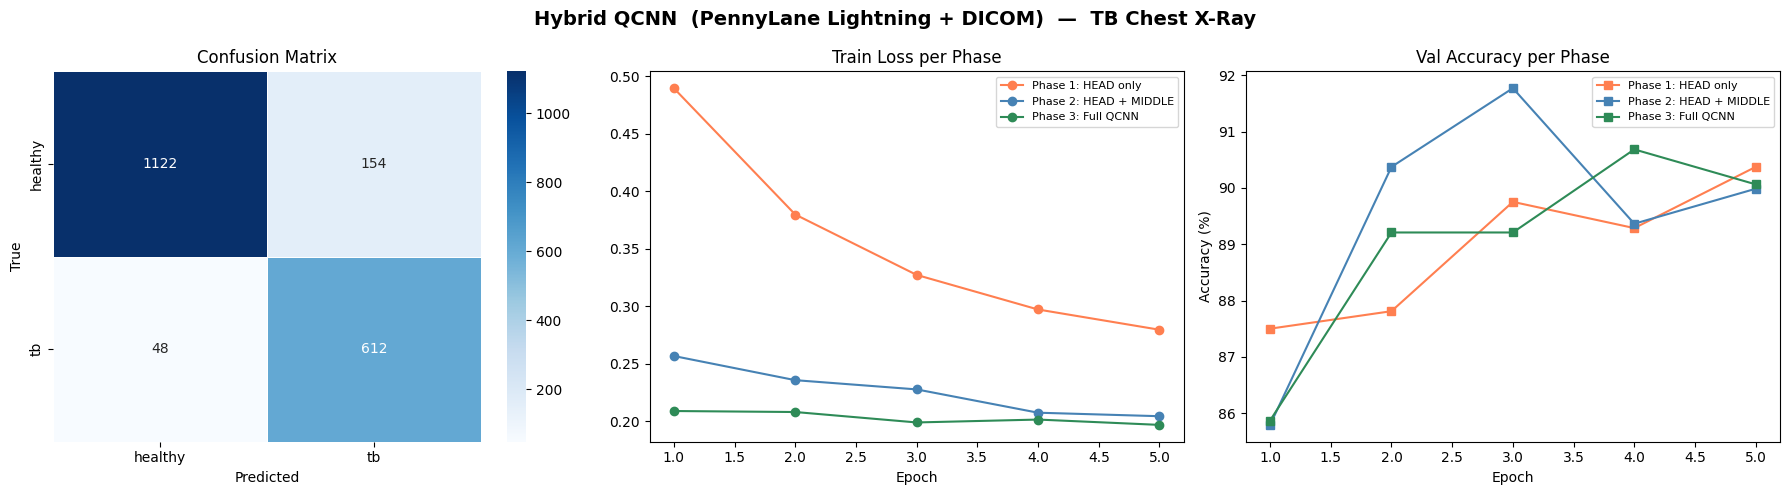

📦 Saved → /kaggle/working/qcnn_training_curves.png


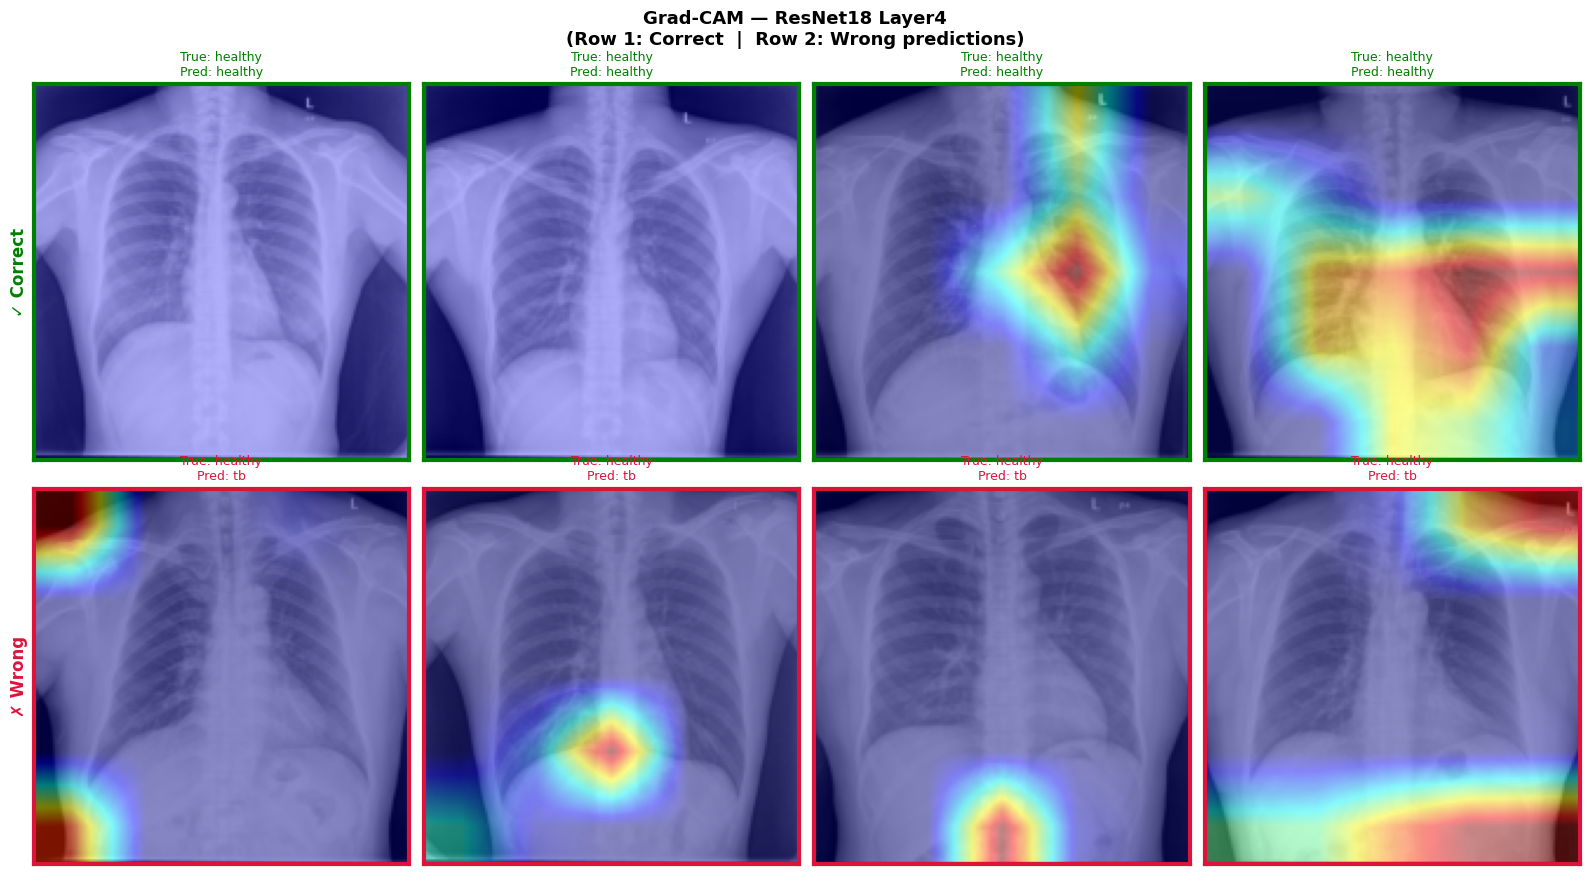

📦 Saved → /kaggle/working/qcnn_gradcam.png

╔══ Hybrid QCNN  (PennyLane Lightning + DICOM) ═══════╗
║  Backbone    : ResNet18 (frozen)                     ║
║  Projector   : 512 → 4 → Tanh → ×π                 ║
║  Quantum     : 4-qubit QCNN  (16 params, 3 layers) ║
║  Diff method : lightning.qubit + adjoint              ║
║  Quantum params  : 16                               ║
║  Classical params: 2,056                            ║
║  DICOM support   : YES ✓                        ║
╚══════════════════════════════════════════════════════╝


✓ Export verified → /kaggle/working/qtb_model_final.pth
  Output shape : torch.Size([1, 2])  |  logits: [-2.285418748855591, 0.10489559173583984]

╔══ Final QCNN Summary ══════════════════════════════════════╗
║  Backend              : lightning.qubit + adjoint           ║
║  Qubits               : 4                              ║
║  QCNN layers          : 3 (HEAD | MIDDLE | BODY)            ║
║  Total quantum params : 16                           

In [5]:
# ╔══════════════════════════════════════════════════════════════════════╗
#  QTB SCAN — Hybrid QCNN for TB Detection
#  Optimised for Kaggle GPU-limited sessions
#
#  Changes vs previous version:
#    1. DICOM support via pydicom (ICMR dataset uses .dicom files)
#    2. DICOMDataset — walks patient subfolders, reads label from filename
#       (e.g. "*_Abnormal.dicom" → TB=1, "*_Normal.dicom" → Normal=0)
#    3. ICMR is TB-only → used as extra TB training data only
#    4. WeightedRandomSampler accounts for the ICMR-inflated TB count
#    5. All other speed-ups retained (lightning.qubit, adjoint, caching)
# ╚══════════════════════════════════════════════════════════════════════╝

# ═══════════════════════════════════════════════════════════════════════
#  CELL 1 — Install
# ═══════════════════════════════════════════════════════════════════════
# !pip install pennylane pennylane-lightning torch torchvision \
#              kagglehub scikit-learn seaborn grad-cam pydicom \
#              Pillow --quiet
#
# Optional GPU backend (needs CUDA + cuQuantum):
# !pip install pennylane-lightning-gpu --quiet

# ═══════════════════════════════════════════════════════════════════════
#  CELL 2 — Imports & Config
# ═══════════════════════════════════════════════════════════════════════
import os, numpy as np, torch, warnings, glob
warnings.filterwarnings("ignore")

# Parallelise lightning.qubit adjoint across CPU cores BEFORE importing pennylane
os.environ.setdefault("OMP_NUM_THREADS", str(os.cpu_count() or 4))

import torch.nn as nn
import torch.optim as optim
from torch.utils.data import (
    DataLoader, WeightedRandomSampler,
    ConcatDataset, TensorDataset, Dataset
)
from torchvision import datasets, models, transforms
import pennylane as qml
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

# DICOM reader — install guard
try:
    import pydicom
    PYDICOM_OK = True
except ImportError:
    PYDICOM_OK = False
    print("⚠  pydicom not found — DICOM images will be skipped. "
          "Run: pip install pydicom")

from PIL import Image
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# ── Globals ─────────────────────────────────────────────────────────────
DEVICE    = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_QUBITS  = 4
IMG_SIZE  = 160          # smaller → faster one-time extraction
BATCH     = 32           # backbone feature-extraction batch size
FEAT_B    = 32           # quantum training batch size (on cached feats)
SEED      = 42
SAVE_DIR  = "/kaggle/working"
ICMR_ROOT = "/kaggle/input/datasets/sowmyaabirami/icmr-tuberclosis-dataset"

torch.manual_seed(SEED)
np.random.seed(SEED)

# ── PennyLane device ─────────────────────────────────────────────────────
dev         = qml.device("lightning.qubit", wires=N_QUBITS)
DIFF_METHOD = "adjoint"

print(f"PyTorch device : {DEVICE}")
print(f"PennyLane      : {qml.__version__}  |  backend: lightning.qubit + {DIFF_METHOD}")
print(f"OMP threads    : {os.environ['OMP_NUM_THREADS']}")
print(f"IMG size       : {IMG_SIZE}px  |  Quantum batch: {FEAT_B}")
print(f"pydicom        : {'available ✓' if PYDICOM_OK else 'MISSING ✗'}")

# ═══════════════════════════════════════════════════════════════════════
#  CELL 3 — DICOM Dataset
#
#  Folder structure expected:
#    ICMR_ROOT/
#      <patient_id>/
#        <hash>_Abnormal.dicom   →  label = 1  (TB)
#        <hash>_Normal.dicom     →  label = 0  (Normal)
#        <hash>.dicom            →  label inferred from parent or skipped
#
#  ICMR dataset is ALL TB (Abnormal), so all files get label = 1.
#  Normal class is sourced from DB1 / DB2 only.
# ═══════════════════════════════════════════════════════════════════════
# Label keywords embedded in DICOM filenames
_DICOM_TB_KEYS     = {"abnormal", "tb", "tuberculosis", "positive", "infected"}
_DICOM_NORMAL_KEYS = {"normal", "healthy", "negative", "non-tb", "no_tb"}

def _label_from_filename(fname: str) -> int | None:
    """
    Parse label from DICOM filename.
    Returns 0 (Normal), 1 (TB), or None (ambiguous → use fallback).
    """
    stem = os.path.splitext(os.path.basename(fname))[0].lower()
    # Check TB keywords first (more specific)
    if any(k in stem for k in _DICOM_TB_KEYS):
        return 1
    if any(k in stem for k in _DICOM_NORMAL_KEYS):
        return 0
    return None          # label unknown — caller decides fallback


def dicom_to_pil(dcm_path: str) -> Image.Image | None:
    """
    Read a .dicom file and return a PIL RGB Image.
    Handles:
      • 8-bit and 16-bit pixel arrays
      • Monochrome1 / Monochrome2 photometric interpretation
      • Missing PhotometricInterpretation tag
    Returns None on any read error.
    """
    if not PYDICOM_OK:
        return None
    try:
        dcm  = pydicom.dcmread(dcm_path, force=True)
        arr  = dcm.pixel_array.astype(np.float32)

        # Normalise to [0, 255]
        a_min, a_max = arr.min(), arr.max()
        if a_max > a_min:
            arr = (arr - a_min) / (a_max - a_min) * 255.0
        else:
            arr = np.zeros_like(arr)

        # Invert Monochrome1 (bright = low density)
        photometric = getattr(dcm, "PhotometricInterpretation", "MONOCHROME2")
        if isinstance(photometric, str) and "MONOCHROME1" in photometric.upper():
            arr = 255.0 - arr

        img_uint8 = arr.astype(np.uint8)

        # Handle multi-frame (take first frame only)
        if img_uint8.ndim == 3 and img_uint8.shape[0] < img_uint8.shape[1]:
            img_uint8 = img_uint8[0]

        pil = Image.fromarray(img_uint8).convert("RGB")
        return pil
    except Exception as e:
        print(f"  ⚠ DICOM read error [{os.path.basename(dcm_path)}]: {e}")
        return None


class DICOMDataset(Dataset):
    """
    Recursively walks `root_dir` for .dicom / .dcm files.

    Label assignment priority:
      1. Keyword in filename (Abnormal → 1, Normal → 0)
      2. `default_label` argument  (used when ICMR is TB-only)

    Args:
        root_dir      : top-level folder to walk
        transform     : torchvision transform pipeline
        default_label : fallback label when filename gives no hint
                        Set to 1 for ICMR (all TB).
        verbose       : print per-file errors
    """
    DICOM_EXTS = {".dicom", ".dcm"}

    def __init__(self,
                 root_dir     : str,
                 transform,
                 default_label: int  = 1,
                 verbose      : bool = False):
        self.transform     = transform
        self.default_label = default_label
        self.verbose       = verbose
        self.samples       = []   # list of (filepath, label)

        if not PYDICOM_OK:
            print("  ✗ DICOMDataset: pydicom unavailable — returning empty dataset.")
            return

        n_skipped = 0
        for dirpath, _, filenames in os.walk(root_dir):
            for fname in filenames:
                ext = os.path.splitext(fname)[1].lower()
                if ext not in self.DICOM_EXTS:
                    continue
                fpath = os.path.join(dirpath, fname)
                label = _label_from_filename(fname)
                if label is None:
                    label = default_label
                # Quick validity check — try reading pixel data
                pil = dicom_to_pil(fpath)
                if pil is None:
                    n_skipped += 1
                    continue
                self.samples.append((fpath, label))

        lbl_counts = {}
        for _, lbl in self.samples:
            lbl_counts[lbl] = lbl_counts.get(lbl, 0) + 1

        print(f"  ✓ DICOMDataset  root : {root_dir}")
        print(f"    Found : {len(self.samples):,} valid DICOM files"
              f"  |  skipped: {n_skipped}"
              f"  |  labels: {lbl_counts}")

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, idx: int):
        fpath, label = self.samples[idx]
        pil = dicom_to_pil(fpath)
        if pil is None:
            # Return a black image if read fails at training time
            pil = Image.new("RGB", (IMG_SIZE, IMG_SIZE), 0)
        if self.transform:
            pil = self.transform(pil)
        return pil, label


# ═══════════════════════════════════════════════════════════════════════
#  CELL 4 — Download Public Datasets
# ═══════════════════════════════════════════════════════════════════════
path1 = kagglehub.dataset_download("tawsifurrahman/tuberculosis-tb-chest-xray-dataset")
path2 = kagglehub.dataset_download("tirthachhetri/tuberclosis-dataset")
print("DB1 (Tawsifur) :", path1)
print("DB2 (Tirtha)   :", path2)
print("ICMR           :", ICMR_ROOT)

# ═══════════════════════════════════════════════════════════════════════
#  CELL 5 — Path Discovery & DataLoaders
# ═══════════════════════════════════════════════════════════════════════
def find_dir(root, target):
    """Walk root; return first directory named `target`, else `root`."""
    for dirpath, dirnames, _ in os.walk(root):
        if os.path.basename(dirpath) == target:
            return dirpath
    return root

db1_root = find_dir(path1, "TB_Chest_Radiography_Database")
tb_train = find_dir(path2, "train")
tb_val   = find_dir(path2, "valid")
tb_test  = find_dir(path2, "test")

print(f"\nDB1 root : {db1_root}")
print(f"DB2      : train={tb_train} | val={tb_val} | test={tb_test}")

# ── Transforms ────────────────────────────────────────────────────────
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# ── Standard datasets (DB1, DB2) ──────────────────────────────────────
extra_ds    = datasets.ImageFolder(db1_root,  transform=train_tf)
split_train = datasets.ImageFolder(tb_train,  transform=train_tf)
val_ds      = datasets.ImageFolder(tb_val,    transform=val_tf)
test_ds     = datasets.ImageFolder(tb_test,   transform=val_tf)
classes     = split_train.classes   # e.g. ['Normal', 'Tuberculosis']

print(f"\nClasses  : {classes}")
print(f"DB2 train: {len(split_train):,}  |  val: {len(val_ds):,}  |  test: {len(test_ds):,}")

# ── ICMR DICOM dataset ────────────────────────────────────────────────
# ICMR contains ONLY TB images → default_label=1, used as extra TB training data.
# Normal class is NOT present in ICMR; sampler will rebalance automatically.
print("\nLoading ICMR DICOM dataset …")
icmr_ds = None
if os.path.exists(ICMR_ROOT) and PYDICOM_OK:
    icmr_ds = DICOMDataset(
        root_dir      = ICMR_ROOT,
        transform     = train_tf,
        default_label = 1,          # All ICMR images are TB
        verbose       = False,
    )
    if len(icmr_ds) == 0:
        print("  ⚠  DICOMDataset is empty — check ICMR_ROOT path and pydicom install.")
        icmr_ds = None
else:
    if not os.path.exists(ICMR_ROOT):
        print(f"  ! ICMR root not found: {ICMR_ROOT}")
    if not PYDICOM_OK:
        print("  ! pydicom not available — DICOM loading skipped.")

# ── Build combined training pool ──────────────────────────────────────
train_parts = [split_train, extra_ds]
if icmr_ds is not None:
    train_parts.append(icmr_ds)

train_ds = ConcatDataset(train_parts)

# Count of ICMR contribution
icmr_count = len(icmr_ds) if icmr_ds is not None else 0
print(f"\nTrain pool       : {len(train_ds):,} images "
      f"(DB2 {len(split_train):,} + DB1 {len(extra_ds):,} + ICMR {icmr_count:,})")
print(f"Val              : {len(val_ds):,}")
print(f"Test             : {len(test_ds):,}")

# ── Collect labels from heterogeneous datasets ────────────────────────
def collect_labels_from_parts(parts):
    """
    Works with ImageFolder (has .targets) and any Dataset (iterates __getitem__).
    Uses fast path for ImageFolder / DICOMDataset.
    """
    labels = []
    for ds in parts:
        if isinstance(ds, datasets.ImageFolder):
            labels += ds.targets
        elif isinstance(ds, DICOMDataset):
            labels += [lbl for _, lbl in ds.samples]
        else:
            labels += [ds[i][1] for i in range(len(ds))]
    return labels

all_labels = collect_labels_from_parts(train_parts)
counts     = np.bincount(all_labels)
print(f"Class counts (train) : {dict(enumerate(counts))}  "
      f"→ [{classes[0]}: {counts[0]:,}, {classes[1]}: {counts[1]:,}]")

# ── WeightedRandomSampler — handles ICMR-inflated TB count ───────────
sample_weights = (1.0 / np.array(counts)[all_labels]).tolist()
sampler        = WeightedRandomSampler(sample_weights, len(sample_weights))

_ldr = dict(num_workers=2,
            pin_memory=(DEVICE.type == "cuda"),
            persistent_workers=True)
train_loader = DataLoader(train_ds, batch_size=BATCH, sampler=sampler, **_ldr)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False,   **_ldr)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False,   **_ldr)
print("DataLoaders ready.")

# ═══════════════════════════════════════════════════════════════════════
#  CELL 6 — PennyLane QCNN Circuit  (lightning.qubit + adjoint)
#
#  3-layer QCNN structure (architecture UNCHANGED):
#    HEAD   (8 params)  : Conv Layer 1   — 2-qubit unitaries on (q0,q1),(q2,q3)
#    MIDDLE (6 params)  : Pool1 (CRZ) + Conv Layer 2 — active qubits q1,q3
#    BODY   (2 params)  : Pool2 (CRZ) + final rotation — output qubit q3
#  Observable : <Z> on qubit 3
# ═══════════════════════════════════════════════════════════════════════
N_H, N_M, N_B = 8, 6, 2
N_WEIGHTS      = N_H + N_M + N_B   # 16

@qml.qnode(dev, interface="torch", diff_method=DIFF_METHOD)
def qcnn_qnode(inputs, weights):
    h = weights[:N_H]
    m = weights[N_H : N_H + N_M]
    b = weights[N_H + N_M :]

    # ── Angle Embedding ──────────────────────────────────────────────
    qml.AngleEmbedding(inputs, wires=range(N_QUBITS), rotation='Y')

    # ── HEAD: Conv Layer 1 ───────────────────────────────────────────
    qml.RY(h[0], wires=0);  qml.RY(h[1], wires=1)
    qml.CNOT(wires=[0, 1])
    qml.RY(h[2], wires=0);  qml.RY(h[3], wires=1)
    qml.RY(h[4], wires=2);  qml.RY(h[5], wires=3)
    qml.CNOT(wires=[2, 3])
    qml.RY(h[6], wires=2);  qml.RY(h[7], wires=3)

    # ── MIDDLE: Pool1 (CRZ) + Conv Layer 2 ──────────────────────────
    qml.CRZ(m[0], wires=[0, 1])
    qml.CRZ(m[1], wires=[2, 3])
    qml.RY(m[2], wires=1);  qml.RY(m[3], wires=3)
    qml.CNOT(wires=[1, 3])
    qml.RY(m[4], wires=1);  qml.RY(m[5], wires=3)

    # ── BODY: Pool2 + final rotation ────────────────────────────────
    qml.CRZ(b[0], wires=[1, 3])
    qml.RY(b[1], wires=3)

    return qml.expval(qml.PauliZ(3))   # scalar per sample

weight_shapes = {"weights": N_WEIGHTS}

# ═══════════════════════════════════════════════════════════════════════
#  CELL 7 — HybridQCNN Model
# ═══════════════════════════════════════════════════════════════════════
class HybridQCNN(nn.Module):
    def __init__(self):
        super().__init__()

        res = models.resnet18(weights="IMAGENET1K_V1")
        for p in res.parameters():
            p.requires_grad = False
        self.backbone  = nn.Sequential(*list(res.children())[:-1])
        self.projector = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, N_QUBITS),
            nn.Tanh()
        )

        self.qlayer = qml.qnn.TorchLayer(qcnn_qnode, weight_shapes)
        with torch.no_grad():
            self.qlayer.weights.uniform_(-np.pi, np.pi)

        self._mask        = torch.zeros(N_WEIGHTS)
        self._mask[:N_H]  = 1.0
        self._hook_handle = None
        self._install_hook()

        self.out_head = nn.Linear(1, 2)
        self._print_summary()

    def _install_hook(self):
        if self._hook_handle is not None:
            self._hook_handle.remove()
        _m = self._mask.clone()
        self._hook_handle = self.qlayer.weights.register_hook(
            lambda grad: grad * _m.to(grad.device)
        )

    def set_phase(self, phase: int):
        mask = torch.zeros(N_WEIGHTS)
        if phase >= 1: mask[:N_H]         = 1.0
        if phase >= 2: mask[N_H:N_H+N_M]  = 1.0
        if phase >= 3: mask[N_H+N_M:]     = 1.0
        self._mask = mask
        self._install_hook()
        labels = {1: "HEAD only", 2: "HEAD + MIDDLE", 3: "HEAD + MIDDLE + BODY"}
        print(f"\n{'─'*58}")
        print(f"  Phase {phase} → {labels[phase]}")
        print(f"  Active quantum params : {int(mask.sum())}/{N_WEIGHTS}")
        print(f"{'─'*58}")

    def _print_summary(self):
        n_q  = N_WEIGHTS
        n_cl = (sum(p.numel() for p in self.projector.parameters()) +
                sum(p.numel() for p in self.out_head.parameters()))
        print("\n╔══ Hybrid QCNN  (PennyLane Lightning + DICOM) ═══════╗")
        print(f"║  Backbone    : ResNet18 (frozen)                     ║")
        print(f"║  Projector   : 512 → {N_QUBITS} → Tanh → ×π                 ║")
        print(f"║  Quantum     : {N_QUBITS}-qubit QCNN  ({N_WEIGHTS} params, 3 layers) ║")
        print(f"║  Diff method : lightning.qubit + adjoint              ║")
        print(f"║  Quantum params  : {n_q:<33}║")
        print(f"║  Classical params: {n_cl:<33,}║")
        print(f"║  DICOM support   : {'YES ✓' if PYDICOM_OK else 'NO (pydicom missing)':<29}║")
        print(f"╚══════════════════════════════════════════════════════╝\n")

    def forward_cached(self, feats):
        """Fast path — feats already (B, 512), backbone skipped."""
        x = self.projector(feats) * np.pi    # (B, N_QUBITS)
        x = self.qlayer(x).unsqueeze(-1)     # (B,) → (B, 1)
        return self.out_head(x)              # (B, 2)

    def forward(self, x):
        """Full path — image input (used for Grad-CAM)."""
        x = self.backbone(x).squeeze(-1).squeeze(-1)   # (B, 512)
        return self.forward_cached(x)

# Instantiate model
model = HybridQCNN().to(DEVICE)

# ═══════════════════════════════════════════════════════════════════════
#  CELL 8 — Backbone Feature Caching  ★ KEY SPEED-UP ★
#
#  ResNet18 is FROZEN → same features every time.
#  Extract ONCE (including DICOM images) → TensorDatasets.
#  Training loop operates purely on cached 512-d vectors — no image I/O.
# ═══════════════════════════════════════════════════════════════════════
def extract_features(loader, backbone, device, desc=""):
    """Run backbone once; return (feats, labels) tensors."""
    backbone.eval().to(device)
    all_feats, all_labels = [], []
    n_batches = len(loader)
    with torch.no_grad():
        for i, (imgs, lbls) in enumerate(loader, 1):
            f = backbone(imgs.to(device))             # (B, 512, 1, 1)
            all_feats.append(f.squeeze(-1).squeeze(-1).cpu())
            all_labels.append(lbls)
            if i % max(1, n_batches // 5) == 0:
                print(f"  {desc}  [{i:4d}/{n_batches}]", end="\r")
    print(f"  {desc}  done.            ")
    return torch.cat(all_feats), torch.cat(all_labels)

print("━━━ Extracting backbone features (one-time, includes DICOM) ━━━")
train_feats, train_lbls = extract_features(train_loader, model.backbone, DEVICE, "Train")
val_feats,   val_lbls   = extract_features(val_loader,   model.backbone, DEVICE, "Val  ")
test_feats,  test_lbls  = extract_features(test_loader,  model.backbone, DEVICE, "Test ")
print(f"\nCached shapes →  train: {tuple(train_feats.shape)}"
      f"  val: {tuple(val_feats.shape)}  test: {tuple(test_feats.shape)}")

# Build fast TensorDatasets
feat_train_ds = TensorDataset(train_feats, train_lbls)
feat_val_ds   = TensorDataset(val_feats,   val_lbls)
feat_test_ds  = TensorDataset(test_feats,  test_lbls)

# Re-apply weighted sampling on cached dataset
_w           = (1.0 / np.array(counts)[train_lbls.numpy()]).tolist()
feat_sampler = WeightedRandomSampler(_w, len(_w))

feat_train_ldr = DataLoader(feat_train_ds, batch_size=FEAT_B, sampler=feat_sampler)
feat_val_ldr   = DataLoader(feat_val_ds,   batch_size=FEAT_B, shuffle=False)
feat_test_ldr  = DataLoader(feat_test_ds,  batch_size=FEAT_B, shuffle=False)
print("Feature DataLoaders ready.  Training will use cached tensors only.")

# ═══════════════════════════════════════════════════════════════════════
#  CELL 9 — Three-Phase Progressive Training  (on cached features)
# ═══════════════════════════════════════════════════════════════════════
PHASES = {
    1: dict(epochs=5, lr=1e-3,  label="HEAD only"),
    2: dict(epochs=5, lr=5e-4,  label="HEAD + MIDDLE"),
    3: dict(epochs=5, lr=2e-4,  label="Full QCNN"),
}
criterion = nn.CrossEntropyLoss()
history   = {"phase": [], "epoch": [], "train_loss": [], "val_acc": []}
best_val  = {1: 0.0, 2: 0.0, 3: 0.0}

for phase, cfg in PHASES.items():
    model.set_phase(phase)
    optimizer = optim.Adam(model.parameters(), lr=cfg['lr'])
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg['epochs'])

    print(f"\n{'═'*60}")
    print(f"  Phase {phase} | {cfg['label']}  —  {cfg['epochs']} epochs")
    print(f"{'═'*60}")

    for epoch in range(1, cfg['epochs'] + 1):

        # ── Train on cached features ───────────────────────────────
        model.train()
        total_loss = 0.0
        for feats, labels in feat_train_ldr:
            feats, labels = feats.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model.forward_cached(feats), labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        # ── Validate on cached features ────────────────────────────
        model.eval()
        correct = total = 0
        with torch.no_grad():
            for feats, labels in feat_val_ldr:
                preds    = model.forward_cached(feats.to(DEVICE)).argmax(1).cpu()
                correct += (preds == labels).sum().item()
                total   += len(labels)

        avg_loss = total_loss / len(feat_train_ldr)
        val_acc  = 100.0 * correct / total
        scheduler.step()

        history["phase"].append(phase)
        history["epoch"].append(epoch)
        history["train_loss"].append(avg_loss)
        history["val_acc"].append(val_acc)

        # ── Checkpoint ─────────────────────────────────────────────
        suffix = ""
        if val_acc > best_val[phase]:
            best_val[phase] = val_acc
            ckpt = os.path.join(SAVE_DIR, f"qcnn_phase{phase}_best.pth")
            torch.save({
                'phase': phase, 'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_acc': val_acc, 'history': history, 'classes': classes,
            }, ckpt)
            suffix = f"  ← ✓ best ({val_acc:.2f}%)"

        print(f"  Epoch {epoch:02d}/{cfg['epochs']} │ "
              f"Loss: {avg_loss:.4f} │ Val Acc: {val_acc:.2f}%{suffix}")

    # ── End-of-phase checkpoint ─────────────────────────────────────
    final_ckpt = os.path.join(SAVE_DIR, f"qcnn_phase{phase}_final.pth")
    torch.save({
        'phase': phase,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'val_acc': val_acc, 'history': history, 'classes': classes,
    }, final_ckpt)
    print(f"\n  📦 Phase {phase} final  → {final_ckpt}")
    print(f"  🏆 Phase {phase} best   → {SAVE_DIR}/qcnn_phase{phase}_best.pth")

# ── Full model save ──────────────────────────────────────────────────
full_path = os.path.join(SAVE_DIR, "qcnn_full_trained.pth")
torch.save({
    'model_state_dict': model.state_dict(),
    'history': history, 'classes': classes,
    'n_qubits': N_QUBITS, 'img_size': IMG_SIZE,
}, full_path)

total_epochs = sum(c['epochs'] for c in PHASES.values())
print(f"\n{'═'*60}")
print(f"  ✓  Progressive training complete")
print(f"     Total epochs : {total_epochs}  |  Phases : 3 / 3")
print(f"     Path : HEAD → HEAD+MIDDLE → FULL QCNN")
print(f"{'═'*60}")

# ═══════════════════════════════════════════════════════════════════════
#  CELL 10 — Test Evaluation
# ═══════════════════════════════════════════════════════════════════════
model.eval()
all_preds, all_true = [], []
with torch.no_grad():
    for feats, labels in feat_test_ldr:
        preds = model.forward_cached(feats.to(DEVICE)).argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_true.extend(labels.numpy())

print("\n── Test Classification Report ──────────────────────────────────")
print(classification_report(all_true, all_preds, target_names=test_ds.classes))

# ═══════════════════════════════════════════════════════════════════════
#  CELL 11 — Plots  (Training Curves + Confusion Matrix)
# ═══════════════════════════════════════════════════════════════════════
phase_colors = {1: "coral", 2: "steelblue", 3: "seagreen"}
fig1, axes = plt.subplots(1, 3, figsize=(18, 5))
fig1.suptitle("Hybrid QCNN  (PennyLane Lightning + DICOM)  —  TB Chest X-Ray",
              fontsize=14, fontweight='bold')

cm = confusion_matrix(all_true, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_ds.classes, yticklabels=test_ds.classes,
            ax=axes[0], linewidths=0.5)
axes[0].set_title("Confusion Matrix")
axes[0].set_ylabel("True"); axes[0].set_xlabel("Predicted")

for ph in [1, 2, 3]:
    idx    = [i for i, p in enumerate(history['phase']) if p == ph]
    epochs = [history['epoch'][i]      for i in idx]
    losses = [history['train_loss'][i] for i in idx]
    accs   = [history['val_acc'][i]    for i in idx]
    axes[1].plot(epochs, losses, color=phase_colors[ph], marker='o',
                 label=f'Phase {ph}: {PHASES[ph]["label"]}')
    axes[2].plot(epochs, accs,   color=phase_colors[ph], marker='s',
                 label=f'Phase {ph}: {PHASES[ph]["label"]}')

axes[1].set_title("Train Loss per Phase");   axes[1].set_xlabel("Epoch"); axes[1].legend(fontsize=8)
axes[2].set_title("Val Accuracy per Phase"); axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Accuracy (%)")
axes[2].legend(fontsize=8)

plt.tight_layout()
curve_path = os.path.join(SAVE_DIR, "qcnn_training_curves.png")
plt.savefig(curve_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"📦 Saved → {curve_path}")

# ═══════════════════════════════════════════════════════════════════════
#  CELL 12 — Grad-CAM  (full forward pass on JPEG test images from DB2)
#
#  Grad-CAM is run on the DB2 test set (standard JPEG X-rays) because:
#    • CAM requires image-space gradients
#    • ICMR DICOM images are not in the test set (TB-only, no ground truth split)
#  Target layer: model.backbone[7] = ResNet18 layer4
# ═══════════════════════════════════════════════════════════════════════
target_layer = [model.backbone[7]]
for p in model.backbone.parameters():
    p.requires_grad_(True)

cam_engine = GradCAM(model=model, target_layers=target_layer)

correct_pool, wrong_pool = [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        preds_b = model(imgs.to(DEVICE)).argmax(1).cpu()
        for i in range(len(labels)):
            entry = (imgs[i], labels[i].item(), preds_b[i].item())
            if preds_b[i] == labels[i] and len(correct_pool) < 4:
                correct_pool.append(entry)
            elif preds_b[i] != labels[i] and len(wrong_pool) < 4:
                wrong_pool.append(entry)
        if len(correct_pool) == 4 and len(wrong_pool) == 4:
            break

MEAN_NP = np.array([0.485, 0.456, 0.406])
STD_NP  = np.array([0.229, 0.224, 0.225])

def denorm(t):
    img = t.numpy().transpose(1, 2, 0) * STD_NP + MEAN_NP
    return np.clip(img, 0, 1).astype(np.float32)

def cam_overlays(pool):
    out = []
    for img_t, lbl, pred in pool:
        inp     = img_t.unsqueeze(0)
        mask    = cam_engine(input_tensor=inp, targets=[ClassifierOutputTarget(pred)])
        overlay = show_cam_on_image(denorm(img_t), mask[0], use_rgb=True, image_weight=0.55)
        out.append((overlay, lbl, pred))
    return out

correct_cams = cam_overlays(correct_pool)
wrong_cams   = cam_overlays(wrong_pool)

n_cols = max(len(correct_cams), len(wrong_cams))
fig2, axes2 = plt.subplots(2, n_cols, figsize=(n_cols * 4, 9))
fig2.suptitle("Grad-CAM — ResNet18 Layer4\n"
              "(Row 1: Correct  |  Row 2: Wrong predictions)",
              fontsize=13, fontweight='bold')

for row_idx, (cams, row_label, color) in enumerate(
        [(correct_cams, "✓ Correct", "green"),
         (wrong_cams,   "✗ Wrong",   "crimson")]):
    for col_idx in range(n_cols):
        ax = axes2[row_idx, col_idx]
        if col_idx < len(cams):
            overlay, true_lbl, pred_lbl = cams[col_idx]
            ax.imshow(overlay)
            ax.set_title(f"True: {test_ds.classes[true_lbl]}\n"
                         f"Pred: {test_ds.classes[pred_lbl]}",
                         fontsize=9, color=color)
            for spine in ax.spines.values():
                spine.set_edgecolor(color); spine.set_linewidth(3)
        else:
            ax.axis('off')
        ax.set_xticks([]); ax.set_yticks([])
    axes2[row_idx, 0].set_ylabel(row_label, fontsize=12,
                                  color=color, fontweight='bold')

plt.tight_layout()
cam_path = os.path.join(SAVE_DIR, "qcnn_gradcam.png")
plt.savefig(cam_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"📦 Saved → {cam_path}")

for p in model.backbone.parameters():
    p.requires_grad_(False)

# ═══════════════════════════════════════════════════════════════════════
#  CELL 13 — Export & Verification
# ═══════════════════════════════════════════════════════════════════════
model.eval()
export_path = os.path.join(SAVE_DIR, "qtb_model_final.pth")
torch.save({
    'model_state_dict': model.state_dict(),
    'classes'         : classes,
    'n_qubits'        : N_QUBITS,
    'img_size'        : IMG_SIZE,
    'history'         : history,
    'best_val_acc'    : best_val,
    'dicom_support'   : PYDICOM_OK,
}, export_path)

# Verify round-trip
chk    = torch.load(export_path, map_location="cpu")
model2 = HybridQCNN()
model2.load_state_dict(chk['model_state_dict'])
model2.eval()
with torch.no_grad():
    dummy_feat = torch.randn(1, 512)
    out        = model2.forward_cached(dummy_feat)
print(f"\n✓ Export verified → {export_path}")
print(f"  Output shape : {out.shape}  |  logits: {out.squeeze().tolist()}")

# ── Final summary ─────────────────────────────────────────────────────
total_params = sum(p.numel() for p in model.parameters())
print(f"\n╔══ Final QCNN Summary ══════════════════════════════════════╗")
print(f"║  Backend              : lightning.qubit + adjoint           ║")
print(f"║  Qubits               : {N_QUBITS:<31}║")
print(f"║  QCNN layers          : 3 (HEAD | MIDDLE | BODY)            ║")
print(f"║  Total quantum params : {N_WEIGHTS:<31}║")
print(f"║  Total model params   : {total_params:<31,}║")
print(f"║  Datasets used        : DB1 + DB2 + ICMR (DICOM)           ║")
print(f"║  ICMR images loaded   : {icmr_count:<31,}║")
print(f"║  Training phases done : 3                                   ║")
print(f"╚════════════════════════════════════════════════════════════╝")

print(f"\n📁 All files in {SAVE_DIR}:")
for f in sorted(os.listdir(SAVE_DIR)):
    fsize = os.path.getsize(os.path.join(SAVE_DIR, f)) / 1e6
    print(f"   {f:<45}  {fsize:.2f} MB")

In [1]:
# ═══════════════════════════════════════════════════════════════════════
#  CELL — Zip & download everything in /kaggle/working/
# ═══════════════════════════════════════════════════════════════════════
import os, zipfile
from IPython.display import FileLink, display

SAVE_DIR = "/kaggle/working"
ZIP_PATH = "/kaggle/working/qtb_all_outputs.zip"

# Remove old zip if re-running
if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir(SAVE_DIR)):
        fpath = os.path.join(SAVE_DIR, fname)
        if os.path.isfile(fpath) and fname != "qtb_all_outputs.zip":
            zf.write(fpath, arcname=fname)
            size_mb = os.path.getsize(fpath) / 1e6
            print(f"  + {fname:<50}  {size_mb:.2f} MB")

zip_mb = os.path.getsize(ZIP_PATH) / 1e6
print(f"\n✓ Zipped → {ZIP_PATH}  ({zip_mb:.2f} MB)")
display(FileLink(ZIP_PATH, result_html_prefix="⬇ Download: "))


✓ Zipped → /kaggle/working/qtb_all_outputs.zip  (0.00 MB)


/kaggle/working/qtb_all_outputs.zip